<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/project/Project8_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA Project Week — Option 8: When Does an Excitatory–Inhibitory Circuit Oscillate?**

**Question.** For a Wilson–Cowan excitatory–inhibitory population model, which combinations of excitatory coupling and external input give a stable state, oscillations or two stable states?

**Minimum result.** Fixed points and their stability (Jacobian trace and determinant) for one parameter set, and a map of the regime over a grid of the excitatory self-coupling and the external input.

**Lessons to revisit.** 6 (eigenvalues and stability), 14 (Jacobian, partial derivatives), 21 and 23 (ODEs, Euler, phase plane, Wilson–Cowan).

**Data.** Simulation only. The model and its parameters are adapted from the Neuromatch Academy Wilson–Cowan tutorial (CC-BY), as in Lesson 23, with time constants in milliseconds.

**How to use this notebook.** Run it top to bottom: it loads the data, shows it, and works one first step for you. Cells marked `# TODO` are yours; each is followed by a check cell that prints *TODO* until your code sets the variables it names, then tests their shapes and simple sanity conditions. Add your own cells freely, but keep every array described by its shape and units.

### Set-up

In [1]:
# SETUP -- run first.
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']   # Okabe-Ito, as in the lessons
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'figure.dpi': 100})
DATA_URL = 'https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/'

def load(name):
    # A local copy (here, or in the repository's data/ folder) first; otherwise download it from the pinned commit.
    for candidate in [name, os.path.join('..', 'data', name), os.path.join('..', '..', 'data', name)]:
        if os.path.exists(candidate):
            return np.load(candidate)
    urllib.request.urlretrieve(DATA_URL + name, name)
    return np.load(name)

def todo(*values):
    # True while any of the values is still None: the check cells below use it to wait for your code.
    return any(v is None for v in values)
print('Set-up complete.')

Set-up complete.


### The model

$$\tau_E\,\dot r_E = -r_E + F_E(w_{EE}r_E - w_{EI}r_I + P), \qquad \tau_I\,\dot r_I = -r_I + F_I(w_{IE}r_E - w_{II}r_I + Q),$$

with $F(x) = \frac{1}{1 + e^{-a(x - \theta)}} - \frac{1}{1 + e^{a\theta}}$, $\tau_E = 10$ ms, $\tau_I = 20$ ms, $a_E = 1.2$, $\theta_E = 2.8$, $a_I = 1$, $\theta_I = 4$. The state is the vector $(r_E, r_I)$ of population activities (unitless, between 0 and 1).

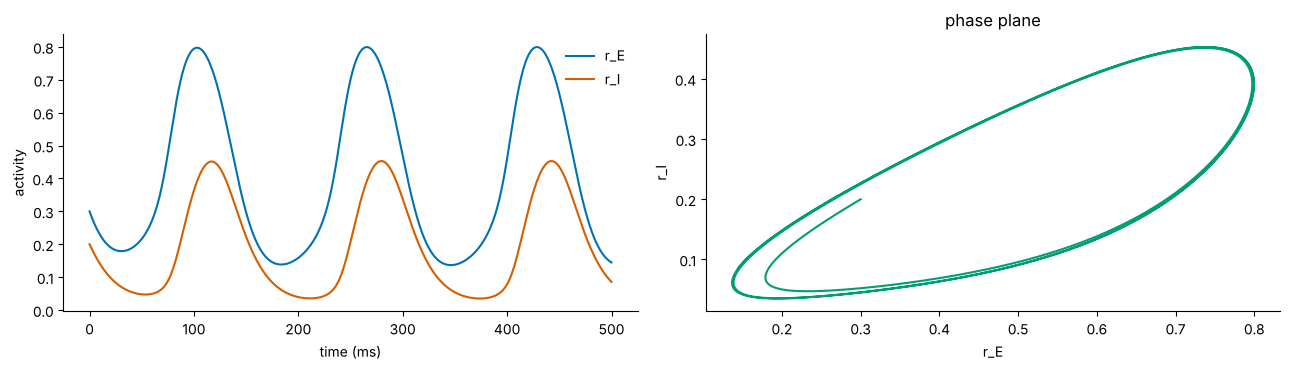

In [2]:
from scipy.optimize import fsolve
BASE = dict(tE=10.0, tI=20.0, aE=1.2, thE=2.8, aI=1.0, thI=4.0, Q=0.0)
SET_OSC = dict(BASE, wEE=6.4, wEI=4.8, wIE=6.0, wII=1.2, P=0.9)        # the oscillating set of Lesson 23
def F(x, a, th):
    with np.errstate(over='ignore'):                           # exp overflows harmlessly to inf for very negative input
        return 1 / (1 + np.exp(-a * (x - th))) - 1 / (1 + np.exp(a * th))
def rhs(x, p):
    rE, rI = x
    return np.array([(-rE + F(p['wEE'] * rE - p['wEI'] * rI + p['P'], p['aE'], p['thE'])) / p['tE'],
                     (-rI + F(p['wIE'] * rE - p['wII'] * rI + p['Q'], p['aI'], p['thI'])) / p['tI']])
def simulate(p, x0, T=500.0, dt=0.1):
    n = int(T / dt); X = np.zeros((n, 2)); X[0] = x0
    for k in range(n - 1):
        X[k + 1] = X[k] + dt * rhs(X[k], p)                   # Euler (Lesson 21)
    return np.arange(n) * dt, X                               # (n,) ms, (n, 2) activities
tt, X = simulate(SET_OSC, [0.3, 0.2])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(tt, X[:, 0], color=PALETTE[0], label='r_E'); axes[0].plot(tt, X[:, 1], color=PALETTE[1], label='r_I')
axes[0].set_xlabel('time (ms)'); axes[0].set_ylabel('activity'); axes[0].legend(frameon=False)
axes[1].plot(X[:, 0], X[:, 1], color=PALETTE[2]); axes[1].set_xlabel('r_E'); axes[1].set_ylabel('r_I'); axes[1].set_title('phase plane')
plt.tight_layout(); plt.show()

### Worked first step: the Jacobian at a fixed point

In [3]:
def jacobian(x, p, h=1e-6):
    J = np.zeros((2, 2))
    for k in range(2):
        e = np.zeros(2); e[k] = h
        J[:, k] = (rhs(x + e, p) - rhs(x - e, p)) / (2 * h)  # central differences (Lesson 9)
    return J
x_star = fsolve(lambda x: rhs(x, SET_OSC), [0.3, 0.2])
J = jacobian(x_star, SET_OSC)
print("fixed point", np.round(x_star, 4), " trace", round(np.trace(J), 4), " det", round(np.linalg.det(J), 5), " eigenvalues", np.round(np.linalg.eigvals(J), 4))

fixed point [0.6183 0.3197]  trace 0.0109  det 0.00406  eigenvalues [0.0054+0.0635j 0.0054-0.0635j]


In [4]:
# TODO 1 -- All fixed points of SET_OSC. Start fsolve from a 6 x 6 grid of initial points in [0, 0.6]^2, keep the distinct
# solutions where |rhs| < 1e-8, and store them in fps (k, 2). For each, store its stability label in labels
# ('stable node', 'stable spiral', 'unstable spiral', 'unstable node' or 'saddle') from the trace, determinant and
# discriminant of its Jacobian.
fps = labels = None

In [5]:
if todo(fps, labels):
    print('TODO 1 not done yet.')
else:
    assert len(fps) == len(labels) >= 1
    print('Check 1 passed.')

TODO 1 not done yet.


In [6]:
# TODO 2 -- Regime map. For wEE on np.linspace(4, 12, 17) and P on np.linspace(0, 2, 17) (other parameters as SET_OSC),
# classify each point: 'oscillation' if a simulation from [0.3, 0.2] still varies (max - min of r_E over the last 200 ms
# above 0.01), else 'bistable' if there are two or more stable fixed points, else 'stable'. Store regime (17, 17) as
# integer codes 0 = stable, 1 = oscillation, 2 = bistable (rows = wEE, columns = P), and show it as an image.
wEE_grid, P_grid = np.linspace(4, 12, 17), np.linspace(0, 2, 17)
regime = None

In [7]:
if todo(regime):
    print('TODO 2 not done yet.')
else:
    assert regime.shape == (17, 17) and set(np.unique(regime)) <= {0, 1, 2}
    print('Check 2 passed.')

TODO 2 not done yet.


In [8]:
# TODO 3 -- Explain one boundary. Pick one point on each side of the stable/oscillation boundary at fixed P, and store
# boundary_eigs = {'stable side': eigenvalues, 'oscillating side': eigenvalues} of the Jacobian at the fixed point.
# (Expect a complex pair whose real part changes sign: a Hopf bifurcation.)
boundary_eigs = None

In [9]:
if todo(boundary_eigs):
    print('TODO 3 not done yet (or no stable/oscillation boundary in your grid: widen it).')
else:
    assert set(boundary_eigs) == {'stable side', 'oscillating side'}
    print('Check 3 passed.')

TODO 3 not done yet (or no stable/oscillation boundary in your grid: widen it).


### Before the talk
- Euler with a 0.1–0.2 ms step: check that halving the step does not change the regime map.
- "Still varies after 400 ms" is a working definition of oscillation; slow transients near a boundary can fool it.
- Stretch: add noise to the input and show how the picture changes near the boundary.